# Notebook B: serve with SGLang and evaluate base vs tuned (one Colab T4 session)
For each model: serve it with SGLang, evaluate the test split with AuditKIT in two modes (plain prompting,
and constrained decoding with `configs/schema.json`), run `sglang.bench_serving`, stop the server.
Results are written and pushed to the HF dataset repo after each model, so a disconnect loses at most the second half.
Set `RUN_BASE` / `RUN_TUNED` below to run one half now and the other later (the tuned half needs Notebook A to have finished).
Needs a Colab secret `HF_TOKEN`. aligntune is never installed here. AuditKIT sends requests one at a time
(its API model is not thread-safe), so each eval mode takes a few minutes.

In [1]:
RUN_BASE = True
RUN_TUNED = True

from google.colab import userdata
from huggingface_hub import HfApi, snapshot_download

HF_USER = "bharataggarwal56"
HF_TOKEN = userdata.get("HF_TOKEN")
assert HF_TOKEN, "Add a Colab secret named HF_TOKEN and enable notebook access"
api = HfApi(token=HF_TOKEN)
assert api.whoami()["name"] == HF_USER, "token belongs to a different account"

BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
TUNED_MODEL = f"{HF_USER}/ticketforge-qwen2.5-1.5b-merged"
DATA_REPO = f"{HF_USER}/ticketforge-data"
TAG = "2026-10-24"

# Stop before installing or starting anything if the tuned model is not on HF yet.
if RUN_TUNED and not api.repo_exists(TUNED_MODEL, repo_type="model"):
    raise RuntimeError(f"{TUNED_MODEL} does not exist yet. Finish Notebook A first, "
                       "or set RUN_TUNED = False to run only the base model.")
print("RUN_BASE", RUN_BASE, "| RUN_TUNED", RUN_TUNED)

RUN_BASE True | RUN_TUNED True


In [2]:
import os, subprocess
SGL_PY = "/content/sgl/bin/python"
def sglang_ok():
    return os.path.exists(SGL_PY) and subprocess.run([SGL_PY, "-c", "import sglang"], capture_output=True).returncode == 0

if not sglang_ok():
    # exact recipe that worked on the T4
    subprocess.run("pip install uv", shell=True, check=True)
    subprocess.run("uv venv --python 3.12 /content/sgl", shell=True, check=True)
    subprocess.run(f"uv pip install --python {SGL_PY} --prerelease=allow sglang ninja", shell=True, check=True)
assert sglang_ok(), "sglang is not importable in /content/sgl"
os.environ["PATH"] = "/content/sgl/bin:/usr/local/cuda/bin:" + os.environ["PATH"]
print(subprocess.run([SGL_PY, "-c", "import sglang; print(sglang.__version__)"], capture_output=True, text=True).stdout)

0.5.22



In [3]:
!pip install -q "auditkit[requests]==1.1.3" jsonschema matplotlib

In [4]:
import json, sys
from pathlib import Path

DATA_DIR = snapshot_download(DATA_REPO, repo_type="dataset", local_dir="/content/ticketforge-data",
                             allow_patterns=["code/*", f"test_{TAG}/*"], token=HF_TOKEN)
sys.path.insert(0, f"{DATA_DIR}/code")
import auditkit as ak
import scorers as sc
from prompt import build_messages

SCHEMA = json.load(open(f"{DATA_DIR}/code/schema.json"))
TEST = f"{DATA_DIR}/test_{TAG}"
SAMPLES = sc.load_samples(f"{TEST}/test/sft_messages.jsonl", f"{TEST}/test_meta.jsonl")
print(len(SAMPLES), "test samples")
RESULTS = Path("/content/results"); RESULTS.mkdir(exist_ok=True)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

300 test samples


## Server helpers (subprocess.Popen in its own process group; no nohup, no pkill)

In [5]:
import signal, time, requests

PORT = 30000
BASE_URL = f"http://127.0.0.1:{PORT}/v1"
READY = "The server is fired up and ready to roll!"

def start_server(model, log_path="/content/sglang.log"):
    log = open(log_path, "w")
    proc = subprocess.Popen(
        [SGL_PY, "-m", "sglang.launch_server", "--model-path", model, "--port", str(PORT),
         "--dtype", "float16", "--attention-backend", "triton", "--sampling-backend", "pytorch"],
        stdout=log, stderr=subprocess.STDOUT, env={**os.environ, "HF_TOKEN": HF_TOKEN},
        start_new_session=True)
    deadline = time.time() + 1200
    while time.time() < deadline:
        text = open(log_path).read()
        if READY in text:
            return proc
        if proc.poll() is not None:
            raise RuntimeError(f"server exited with {proc.returncode}:\n" + text[-3000:])
        time.sleep(5)
    stop_server(proc)
    raise TimeoutError("server not ready after 20 min:\n" + open(log_path).read()[-3000:])

def gpu_used_mib():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout
    return int(out.split()[0])

def stop_server(proc):
    if proc.poll() is None:
        os.killpg(os.getpgid(proc.pid), signal.SIGTERM)
        try:
            proc.wait(60)
        except subprocess.TimeoutExpired:
            os.killpg(os.getpgid(proc.pid), signal.SIGKILL)
            proc.wait()
    for _ in range(30):
        if gpu_used_mib() < 500:
            return
        time.sleep(2)
    print("warning: GPU memory still in use:", gpu_used_mib(), "MiB")

def rf(schema):
    return {"type": "json_schema", "json_schema": {"name": "ticket", "schema": schema}}

## Evaluate and benchmark one model

In [6]:
BENCH_KEYS = ["completed", "request_throughput", "output_throughput", "total_throughput",
              "mean_e2e_latency_ms", "median_e2e_latency_ms", "p99_e2e_latency_ms", "mean_ttft_ms", "mean_itl_ms"]

def bench(model, mode, schema_served):
    out = f"/content/bench_{mode}.jsonl"
    if os.path.exists(out):
        os.remove(out)
    for module in ("sglang.bench_serving", "sglang.benchmark.serving"):
        cmd = [SGL_PY, "-m", module, "--backend", "sglang-oai-chat", "--host", "127.0.0.1", "--port", str(PORT),
               "--model", model, "--dataset-name", "random", "--random-input-len", "310",
               "--random-output-len", "52", "--random-range-ratio", "1.0", "--num-prompts", "200",
               "--max-concurrency", "16", "--output-file", out, "--disable-tqdm"]
        if mode == "constrained":
            cmd += ["--extra-request-body", json.dumps({"response_format": rf(schema_served)})]
        p = subprocess.run(cmd, capture_output=True, text=True, env={**os.environ, "HF_TOKEN": HF_TOKEN})
        if p.returncode == 0 and os.path.exists(out):
            row = json.loads(open(out).read().strip().splitlines()[-1])
            return {k: row.get(k) for k in BENCH_KEYS} | {"module": module}
        print(module, "failed:", (p.stderr or p.stdout)[-1500:])
    raise RuntimeError("bench_serving failed with both module names")

def evaluate_mode(model, mode, schema_served):
    extra = {"response_format": rf(schema_served)} if mode == "constrained" else {}
    res = ak.evaluate(SAMPLES, model=f"api:{model}", api_base=BASE_URL, api_key="EMPTY",
                      scorers=sc.make_scorers(SCHEMA), adapter=sc.prompt_adapter(),
                      config=ak.RunConfig(temperature=0, max_tokens=256, concurrency=1), **extra)
    by_id = {p.sample_id: p.raw_output or "" for p in res.samples}
    outputs = [by_id[s.id] for s in SAMPLES]
    return {"headline": res.headline, "perf": res.perf,
            "hard_case": sc.slice_by_hard_case(outputs, SAMPLES, SCHEMA),
            "sample_outputs": outputs[:5]}

def run_model(tag, model, out_name):
    proc = start_server(model)
    try:
        # The constrained schema is the full one unless the server rejects the summary pattern (risk R3).
        probe = {"model": model, "messages": build_messages(SAMPLES[0].input), "temperature": 0,
                 "max_tokens": 256, "response_format": rf(SCHEMA)}
        served, schema_used = SCHEMA, "full"
        r = requests.post(f"{BASE_URL}/chat/completions", json=probe, timeout=300)
        if r.status_code != 200:
            print("full schema rejected:", r.status_code, r.text[:300], "-> retrying without the summary pattern")
            served, schema_used = sc.strip_pattern(SCHEMA), "no_summary_pattern"
            probe["response_format"] = rf(served)
            r = requests.post(f"{BASE_URL}/chat/completions", json=probe, timeout=300)
            r.raise_for_status()
        result = {"tag": tag, "model": model, "schema_used": schema_used, "modes": {}}
        for mode in ("plain", "constrained"):
            t0 = time.time()
            m = evaluate_mode(model, mode, served)
            m["bench"] = bench(model, mode, served)
            m["eval_seconds"] = round(time.time() - t0, 1)
            result["modes"][mode] = m
            print(tag, mode, {k: round(v, 3) for k, v in m["headline"].items() if k in ("schema_valid", "exact_match_fields")})
    finally:
        stop_server(proc)
    path = RESULTS / out_name
    path.write_text(json.dumps(result, indent=2, default=str))
    api.upload_file(path_or_fileobj=str(path), path_in_repo=f"results/{out_name}",
                    repo_id=DATA_REPO, repo_type="dataset", commit_message=f"Add {out_name}")
    print("saved and pushed", out_name)
    return result

In [7]:
if RUN_BASE:
    base = run_model("base", BASE_MODEL, "baseline.json")
else:
    print("RUN_BASE is False; skipping the base model")

full schema rejected: 400 {"object":"error","message":"Failed to compile json grammar: JSON Schema at #/properties/summary is not supported by xgrammar: constraints pattern, minLength/maxLength cannot be enforced together","type":"BadRequestError","param":null,"code":400} -> retrying without the summary pattern
base plain {'schema_valid': 0.0, 'exact_match_fields': 0.0}
base constrained {'schema_valid': 0.973, 'exact_match_fields': 0.027}
saved and pushed baseline.json


In [8]:
if RUN_TUNED:
    tuned = run_model("tuned", TUNED_MODEL, "tuned.json")
else:
    print("RUN_TUNED is False; skipping the tuned model")

full schema rejected: 400 {"object":"error","message":"Failed to compile json grammar: JSON Schema at #/properties/summary is not supported by xgrammar: constraints pattern, minLength/maxLength cannot be enforced together","type":"BadRequestError","param":null,"code":400} -> retrying without the summary pattern
tuned plain {'schema_valid': 1.0, 'exact_match_fields': 0.533}
tuned constrained {'schema_valid': 1.0, 'exact_match_fields': 0.533}
saved and pushed tuned.json


## 2x2 table, hard_case slices, and chart (runs once both result files exist)

## 2x2: base/tuned x plain/constrained (test split, n=300)

| model / mode | schema-valid | exact match | category | priority | product | sentiment | needs_human | summary F1 | mean latency ms | req/s | out tok/s |
|---|---|---|---|---|---|---|---|---|---|---|---|
| base / plain | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 4824 | 3.25 | 169 |
| base / constrained | 0.973 | 0.027 | 0.660 | 0.263 | 0.987 | 0.537 | 0.557 | 0.245 | 2734 | 5.71 | 297 |
| tuned / plain | 1.000 | 0.533 | 0.937 | 0.697 | 1.000 | 0.937 | 0.840 | 0.423 | 4230 | 3.70 | 192 |
| tuned / constrained | 1.000 | 0.533 | 0.937 | 0.700 | 1.000 | 0.937 | 0.840 | 0.423 | 2738 | 5.74 | 298 |

Latency and throughput are from `sglang.bench_serving` (random prompts, 310 in / 52 out tokens, concurrency 16);
the constrained rows send `response_format` with the schema.

## exact match (5 structured fields) by hard_case

| model / mode | all | none | typo | ambiguous | mixed | multi |
|---|---|---|---|---|---|

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nt/results/comparison.png: 100%|##########|  107kB /  107kB            

Validating                    :           |   0%            

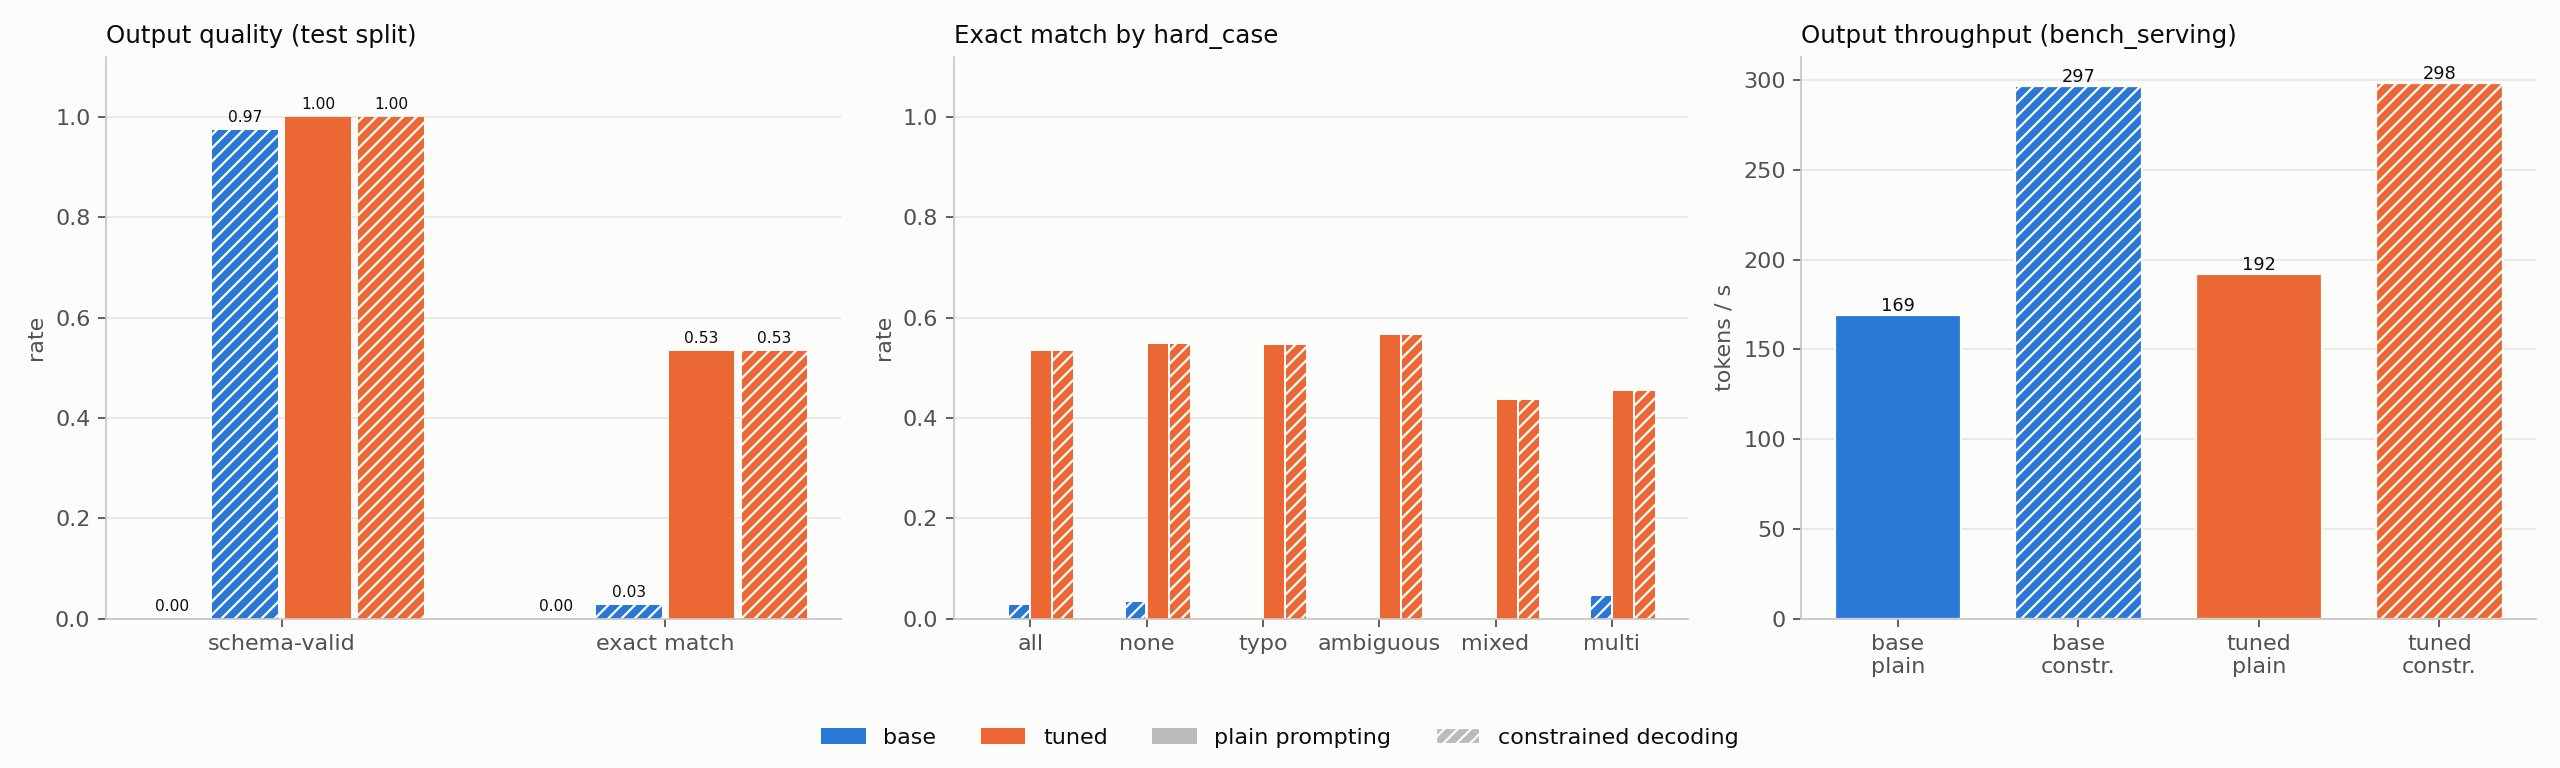

In [9]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def load_result(name):
    p = RESULTS / name
    if not p.exists():
        try:
            from huggingface_hub import hf_hub_download
            p = Path(hf_hub_download(DATA_REPO, f"results/{name}", repo_type="dataset", token=HF_TOKEN))
        except Exception:
            return None
    return json.loads(p.read_text())

def make_report(base, tuned, out_dir):
    out_dir = Path(out_dir)
    cols = [("schema_valid", "schema-valid"), ("exact_match_fields", "exact match"), ("category_acc", "category"),
            ("priority_acc", "priority"), ("product_acc", "product"), ("sentiment_acc", "sentiment"),
            ("needs_human_acc", "needs_human"), ("summary_f1", "summary F1")]
    runs = [(f"{r['tag']} / {mode}", r, mode) for r in (base, tuned) for mode in ("plain", "constrained")]
    lines = ["## 2x2: base/tuned x plain/constrained (test split, n=%d)" % runs[0][1]["modes"]["plain"]["hard_case"]["all"]["n"], "",
             "| model / mode | " + " | ".join(c[1] for c in cols) + " | mean latency ms | req/s | out tok/s |",
             "|" + "---|" * (len(cols) + 4)]
    for name, r, mode in runs:
        m = r["modes"][mode]
        b = m["bench"]
        lines.append(f"| {name} | " + " | ".join(f"{m['headline'][k]:.3f}" for k, _ in cols)
                     + f" | {b['mean_e2e_latency_ms']:.0f} | {b['request_throughput']:.2f} | {b['output_throughput']:.0f} |")
    lines += ["", "Latency and throughput are from `sglang.bench_serving` (random prompts, 310 in / 52 out tokens, concurrency 16);",
              "the constrained rows send `response_format` with the schema.", "",
              "## exact match (5 structured fields) by hard_case", "",
              "| model / mode | " + " | ".join(base["modes"]["plain"]["hard_case"]) + " |",
              "|" + "---|" * (len(base["modes"]["plain"]["hard_case"]) + 1)]
    cases = list(base["modes"]["plain"]["hard_case"])
    for name, r, mode in runs:
        hc = r["modes"][mode]["hard_case"]
        lines.append(f"| {name} | " + " | ".join(f"{hc[c]['exact_match_fields']:.3f} (n={hc[c]['n']})" for c in cases) + " |")
    (out_dir / "comparison.md").write_text("\n".join(lines) + "\n")

    ink, muted, surface = "#0b0b0b", "#52514e", "#fcfcfb"
    color = {"base": "#2a78d6", "tuned": "#eb6834"}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor=surface)
    def style(ax, title, ylabel):
        ax.set_facecolor(surface); ax.set_title(title, loc="left", color=ink, fontsize=11)
        ax.set_ylabel(ylabel, color=muted); ax.tick_params(colors=muted)
        for s in ("top", "right"): ax.spines[s].set_visible(False)
        for s in ("left", "bottom"): ax.spines[s].set_color("#c9c8c3")
        ax.grid(axis="y", color="#e8e7e2", linewidth=0.8); ax.set_axisbelow(True)
    def bars(ax, groups, getter, width=0.19, labels=True):
        for j, (name, r, mode) in enumerate(runs):
            xs = [i + (j - 1.5) * width for i in range(len(groups))]
            vals = [getter(r, mode, g) for g in groups]
            ax.bar(xs, vals, width * 0.9, color=color[r["tag"]], edgecolor=surface,
                   hatch="////" if mode == "constrained" else None, linewidth=0)
            for x, v in zip(xs, vals if labels else []):
                ax.text(x, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color=ink)
        ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups)
    bars(axes[0], ["schema_valid", "exact_match_fields"], lambda r, m, g: r["modes"][m]["headline"][g])
    axes[0].set_xticklabels(["schema-valid", "exact match"]); axes[0].set_ylim(0, 1.12)
    style(axes[0], "Output quality (test split)", "rate")
    bars(axes[1], cases, lambda r, m, g: r["modes"][m]["hard_case"][g]["exact_match_fields"], labels=False)
    axes[1].set_ylim(0, 1.12); style(axes[1], "Exact match by hard_case", "rate")
    for j, (name, r, mode) in enumerate(runs):
        v = r["modes"][mode]["bench"]["output_throughput"]
        axes[2].bar(j, v, 0.7, color=color[r["tag"]], edgecolor=surface, hatch="////" if mode == "constrained" else None)
        axes[2].text(j, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=ink)
    axes[2].set_xticks(range(4)); axes[2].set_xticklabels(["base\nplain", "base\nconstr.", "tuned\nplain", "tuned\nconstr."])
    style(axes[2], "Output throughput (bench_serving)", "tokens / s")
    fig.legend(handles=[Patch(facecolor=color["base"], label="base"), Patch(facecolor=color["tuned"], label="tuned"),
                        Patch(facecolor="#bbbbbb", label="plain prompting"),
                        Patch(facecolor="#bbbbbb", hatch="////", edgecolor=surface, label="constrained decoding")],
               loc="lower center", ncol=4, frameon=False, labelcolor=ink)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.savefig(out_dir / "comparison.png", dpi=160, facecolor=surface)
    plt.close(fig)
    return "\n".join(lines)

base_r, tuned_r = load_result("baseline.json"), load_result("tuned.json")
if base_r and tuned_r:
    print(make_report(base_r, tuned_r, RESULTS))
    for name in ("comparison.md", "comparison.png"):
        api.upload_file(path_or_fileobj=str(RESULTS / name), path_in_repo=f"results/{name}",
                        repo_id=DATA_REPO, repo_type="dataset", commit_message=f"Add {name}")
    from IPython.display import Image, display
    display(Image(str(RESULTS / "comparison.png")))
else:
    print("Need both baseline.json and tuned.json; run the other half, then re-run this cell.")